In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler

In [3]:
DATA_DIR = Path("data/CMaps")

index_cols = ["engine_id", "time_in_cycles"]
setting_cols = [f"setting_{i}" for i in range(1, 4)]
sensor_cols = [
    "T2",
    "T24",
    "T30",
    "T50",
    "P2",
    "P15",
    "P30",
    "Nf",
    "Nc",
    "epr",
    "Ps30",
    "phi",
    "NRf",
    "NRc",
    "BPR",
    "farB",
    "htBleed",
    "Nf_dmd",
    "PCNfR_dmd",
    "W31",
    "W32",
]
columns = index_cols + setting_cols + sensor_cols

fd001_train_ds = pd.read_csv(
    DATA_DIR / "train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns,
)

display(fd001_train_ds.head())
fd001_train_ds.describe()

,engine_id,time_in_cycles,setting_1,setting_2,setting_3,T2,T24,T30,T50,P2,...,phi,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,engine_id,time_in_cycles,setting_1,setting_2,setting_3,T2,T24,T30,T50,P2,...,phi,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


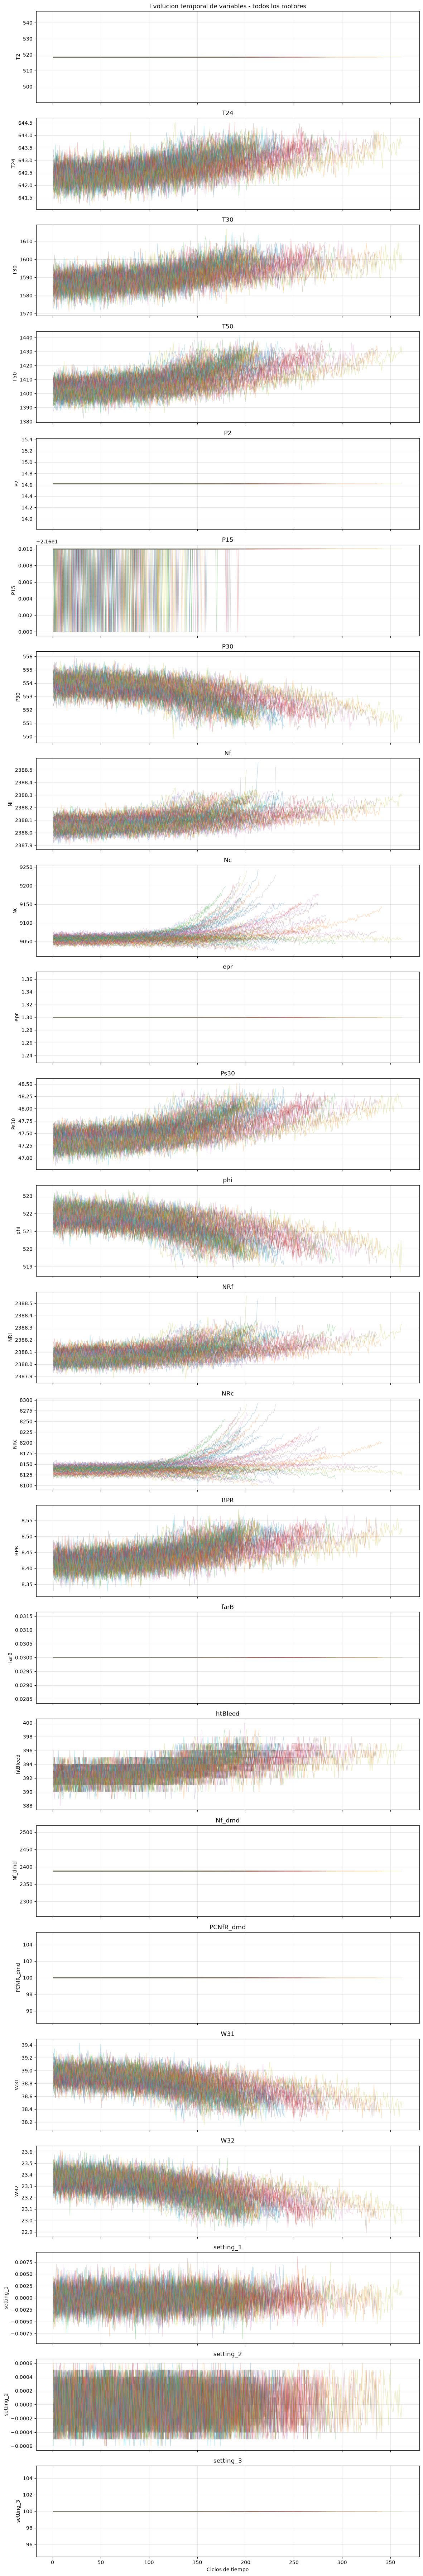

In [4]:
# En el caso de querer jugar con esta función, si se pone engine_id=None se muestran...\
# todos los motores. Tambien se puede jugar con variables_cols como slice para mostrar solo algunas variables.


def plot_variables_for_engine(
    df,
    variables_cols,
    engine_id=None,
):
    if engine_id is None:
        grouped_data = df.groupby("engine_id")
        title = "Evolucion temporal de variables - todos los motores"
    else:
        grouped_data = [(engine_id, df[df["engine_id"] == engine_id])]
        title = f"Evolucion temporal de variables - motor {engine_id}"

    n_rows = len(variables_cols)

    fig, axes = plt.subplots(
        n_rows,
        1,
        figsize=(12, 3 * n_rows),
        sharex=True,
    )
    axes = [axes] if n_rows == 1 else axes.flatten()

    for ax, sensor in zip(axes, variables_cols):
        for _, engine_data in grouped_data:
            ax.plot(
                engine_data["time_in_cycles"],
                engine_data[sensor],
                alpha=0.25 if engine_id is None else 1,
                linewidth=1,
            )
        ax.set_title(sensor)
        ax.set_ylabel(sensor)
        ax.grid(alpha=0.3)

    axes[0].set_title(title)
    axes[-1].set_xlabel("Ciclos de tiempo")
    fig.tight_layout()
    plt.show()


variables_cols = sensor_cols + setting_cols
plot_variables_for_engine(fd001_train_ds, variables_cols=variables_cols, engine_id=None)
# plot_variables_for_engine(fd001_train_ds, variables_cols=variables_cols, engine_id=1)

In [5]:
# Cogemos las variables que no tienen apenas desviación y los quitamos
# Especial atención con el sensor p15 que su desviación no es exactamente 0...\
# pero es practicamente 0, con algunas desviaciones puntuales
fd001_train_ds.drop(
    columns=["T2", "P2", "P15", "epr", "farB", "Nf_dmd", "PCNfR_dmd", "setting_3"],
    inplace=True,
)

Etiqueta RUL en el dataset de entrenamiento

In [6]:
max_cycles = fd001_train_ds.groupby("engine_id")["time_in_cycles"].transform("max")
fd001_train_ds["RUL"] = max_cycles - fd001_train_ds["time_in_cycles"]

display(
    fd001_train_ds.groupby("engine_id")[["engine_id", "time_in_cycles", "RUL"]].tail()
)

,engine_id,time_in_cycles,RUL
187,1,188,4
188,1,189,3
189,1,190,2
190,1,191,1
191,1,192,0
...,...,...,...
20626,100,196,4
20627,100,197,3
20628,100,198,2
20629,100,199,1


Separación de validación por motor

Separo 20 motores completos para validación antes de las correlaciones y del escalado, para que ni la selección de variables ni el `MinMaxScaler` vean datos de validación. La partición se hace por `engine_id` para que un mismo motor no quede repartido entre train y validación.

In [7]:
N_VAL_ENGINES = 20
RANDOM_STATE = 42

splitter = GroupShuffleSplit(
    n_splits=1, test_size=N_VAL_ENGINES, random_state=RANDOM_STATE
)
train_idx, val_idx = next(
    splitter.split(fd001_train_ds, groups=fd001_train_ds["engine_id"])
)

fd001_val_ds = fd001_train_ds.iloc[val_idx].reset_index(drop=True)
fd001_train_ds = fd001_train_ds.iloc[train_idx].reset_index(drop=True)

val_engines = sorted(fd001_val_ds["engine_id"].unique().tolist())

print(f"Motores de entrenamiento: {fd001_train_ds['engine_id'].nunique()}")
print(f"Motores de validación: {len(val_engines)} -> {val_engines}")

Motores de entrenamiento: 80
Motores de validación: 20 -> [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]


In [8]:
correlation_matrix = fd001_train_ds.corr()

rul_correlations = (
    correlation_matrix["RUL"]
    .drop(["RUL", "engine_id", "time_in_cycles"])
    .sort_values(key=lambda values: values.abs())
)

display(rul_correlations.to_frame("correlation_with_RUL"))

,correlation_with_RUL
setting_2,0.006393
setting_1,-0.006760
NRc,-0.308297
Nc,-0.386597
NRf,-0.547568
Nf,-0.551068
T30,-0.575123
htBleed,-0.595801
T24,-0.596959
W31,0.618565


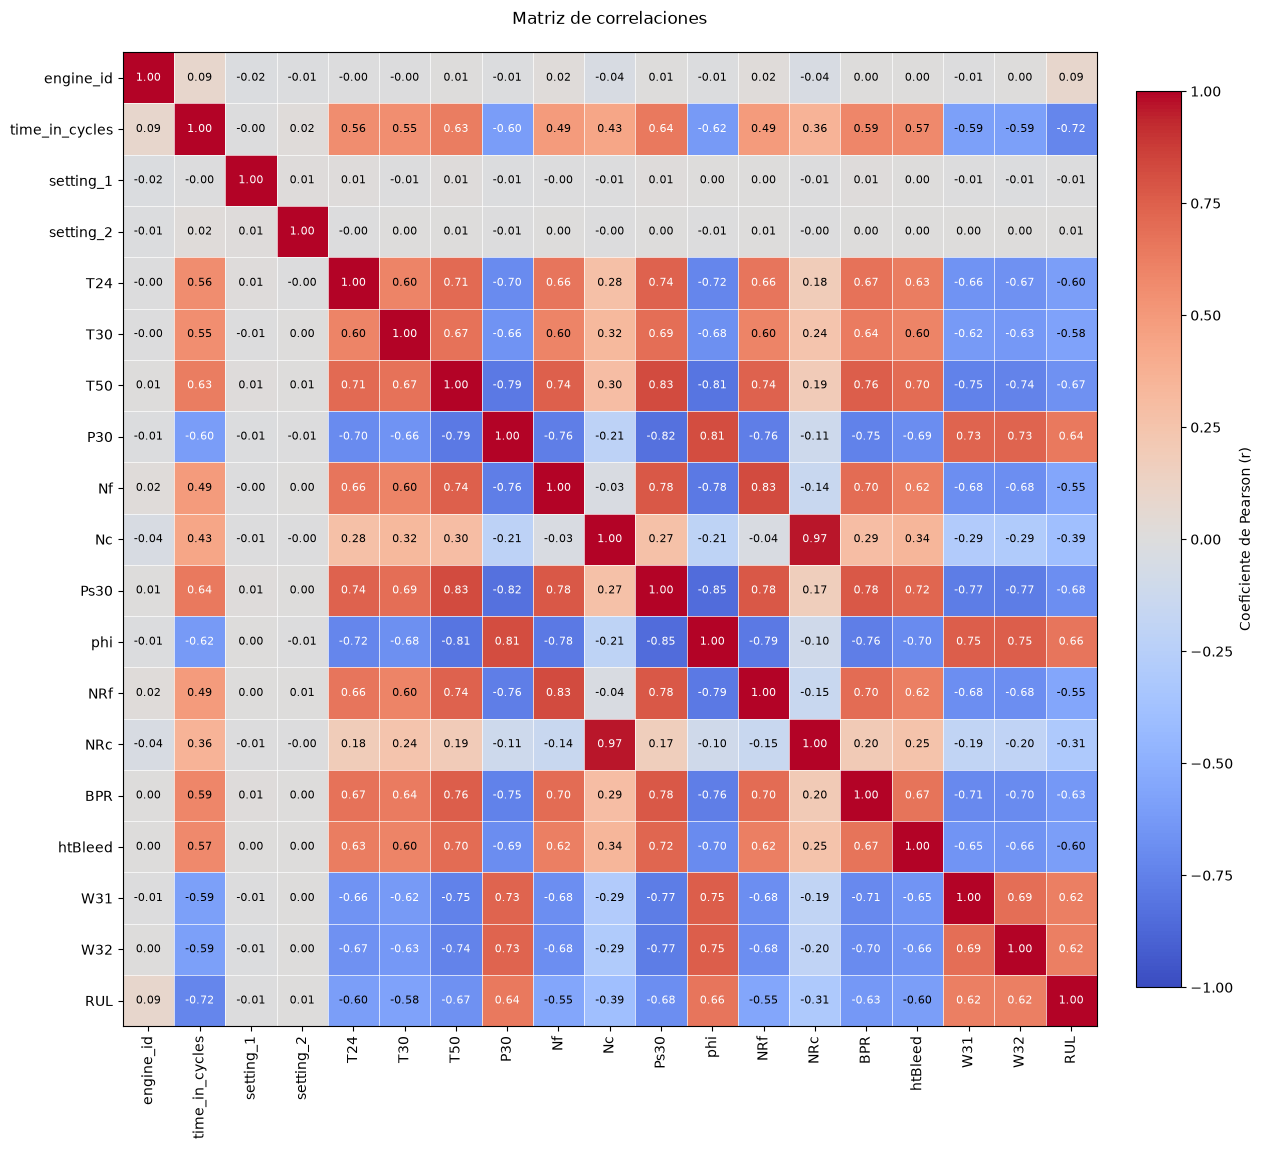

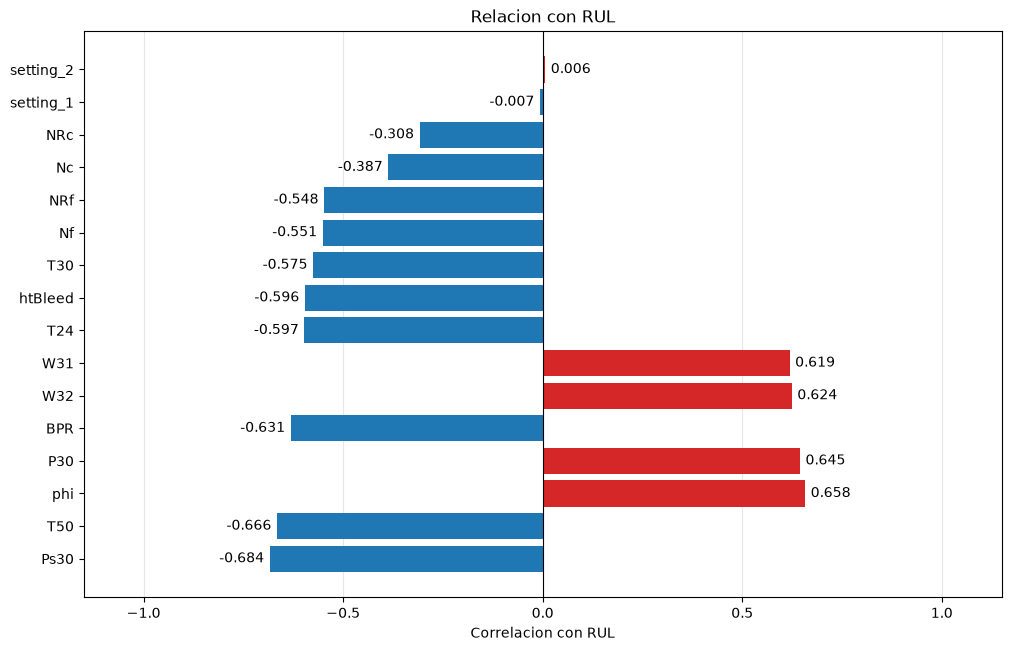

In [14]:
n_variables = len(correlation_matrix)
fig, ax = plt.subplots(
    figsize=(max(12, 0.65 * n_variables), max(10, 0.6 * n_variables)),
    layout="constrained",
)

cmap = plt.get_cmap("coolwarm").copy()
cmap.set_bad("#e5e7eb")
im = ax.imshow(correlation_matrix, cmap=cmap, vmin=-1, vmax=1)
colorbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
colorbar.set_label("Coeficiente de Pearson (r)")

ax.set_xticks(range(n_variables), labels=correlation_matrix.columns, rotation=90)
ax.set_yticks(range(n_variables), labels=correlation_matrix.index)
ax.set_xticks([i - 0.5 for i in range(n_variables + 1)], minor=True)
ax.set_yticks([i - 0.5 for i in range(n_variables + 1)], minor=True)
ax.grid(which="minor", color="white", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)

for row in range(n_variables):
    for col in range(n_variables):
        value = correlation_matrix.iloc[row, col]
        label = "N/D" if pd.isna(value) else f"{value:.2f}"
        ax.text(
            col,
            row,
            label,
            ha="center",
            va="center",
            fontsize=8,
            color="white" if pd.notna(value) and abs(value) >= 0.6 else "black",
        )

ax.set_title(
    "Matriz de correlaciones\n",
)
plt.show()

fig, ax = plt.subplots(
    figsize=(10, max(4, 0.4 * len(rul_correlations))), layout="constrained"
)
colors = ["tab:red" if value >= 0 else "tab:blue" for value in rul_correlations]
bars = ax.barh(rul_correlations.index, rul_correlations.values, color=colors)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1.15, 1.15)
ax.set_xticks([-1, -0.5, 0, 0.5, 1])
ax.set_xlabel("Correlacion con RUL")
ax.set_title("Relacion con RUL")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.3)
plt.show()

Las variables NRc y Nc tiene una correlación muy altas entre ellas, por lo que conviene eliminar una de ellas. En este caso, decido quitar NRc por tener menor correlación con RUL que Nc.

Asi mismo, si vemos la relación de las variable con respeco a RUL, las dos condiciones operacionales no muestran ninguna correlación con RUL, por lo que tambien las borro

In [10]:
# Las variables NRc y Nc tiene una correlación muy altas entre ellas
fd001_train_ds.drop(columns=["setting_1", "setting_2", "NRc"], inplace=True)
fd001_val_ds.drop(columns=["setting_1", "setting_2", "NRc"], inplace=True)

Normalización con Min-Max

In [ ]:
columns_to_normalize = [
    col
    for col in fd001_train_ds.columns
    if col not in ["engine_id", "time_in_cycles", "RUL"]
]

min_max_scaler = MinMaxScaler()

fd001_train = fd001_train_ds.copy()
fd001_train[columns_to_normalize] = min_max_scaler.fit_transform(
    fd001_train_ds[columns_to_normalize]
)

fd001_val = fd001_val_ds.copy()
fd001_val[columns_to_normalize] = min_max_scaler.transform(
    fd001_val_ds[columns_to_normalize]
)

display(fd001_train.head())
display(fd001_val.head())

,engine_id,time_in_cycles,T24,T30,T50,P30,Nf,Nc,Ps30,phi,NRf,BPR,htBleed,W31,W32,RUL
0,2,1,0.204819,0.279049,0.108171,0.753623,0.166667,0.148030,0.047904,0.776119,0.264706,0.243675,0.250000,0.620155,0.779205,286
1,2,2,0.183735,0.349030,0.141030,0.792271,0.121212,0.132729,0.233533,0.855011,0.147059,0.345660,0.333333,0.713178,0.710163,285
2,2,3,0.102410,0.376717,0.244583,0.851852,0.212121,0.145876,0.221557,0.829424,0.161765,0.203581,0.250000,0.751938,0.732947,284
3,2,4,0.141566,0.285808,0.193428,0.708535,0.121212,0.162793,0.149701,0.810235,0.073529,0.287661,0.250000,0.767442,0.840238,283
4,2,5,0.156627,0.174188,0.307815,0.848631,0.196970,0.163421,0.239521,0.763326,0.088235,0.228883,0.166667,0.806202,0.730737,282


,engine_id,time_in_cycles,T24,T30,T50,P30,Nf,Nc,Ps30,phi,NRf,BPR,htBleed,W31,W32,RUL
0,1,1,0.183735,0.406802,0.273712,0.726248,0.242424,0.109755,0.371257,0.633262,0.205882,0.356559,0.333333,0.713178,0.724662,191
1,1,2,0.283133,0.453019,0.318828,0.628019,0.212121,0.100242,0.383234,0.765458,0.279412,0.404438,0.333333,0.666667,0.731014,190
2,1,3,0.343373,0.369523,0.337655,0.710145,0.272727,0.140043,0.251497,0.795309,0.220588,0.349942,0.166667,0.627907,0.621375,189
3,1,4,0.343373,0.256159,0.296270,0.740741,0.318182,0.124518,0.167665,0.889126,0.294118,0.156870,0.333333,0.573643,0.662386,188
4,1,5,0.349398,0.257467,0.373535,0.668277,0.242424,0.149960,0.257485,0.746269,0.235294,0.395095,0.416667,0.589147,0.704502,187


In [12]:
# Ajusto el dataset de test para que tenga las mismas columnas que el dataset de train,...\
# y calculo el RUL para cada motor

dropped_cols = [
    "T2",
    "P2",
    "P15",
    "epr",
    "farB",
    "Nf_dmd",
    "PCNfR_dmd",
    "setting_1",
    "setting_2",
    "setting_3",
    "NRc",
]

fd001_test_ds = pd.read_csv(
    DATA_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=columns
)
fd001_test_ds = fd001_test_ds.drop(columns=dropped_cols)

# Para el RUL del test, final dado + ciclos que faltan hasta el último observado
final_rul = pd.read_csv(DATA_DIR / "RUL_FD001.txt", header=None).iloc[:, 0]
final_rul.index += 1

max_cycles_test = fd001_test_ds.groupby("engine_id")["time_in_cycles"].transform("max")
fd001_test_ds["RUL"] = (
    fd001_test_ds["engine_id"].map(final_rul)
    + max_cycles_test
    - fd001_test_ds["time_in_cycles"]
)
fd001_test = fd001_test_ds.copy()
fd001_test[columns_to_normalize] = min_max_scaler.transform(
    fd001_test_ds[columns_to_normalize]
)

display(fd001_test.head())

,engine_id,time_in_cycles,T24,T30,T50,P30,Nf,Nc,Ps30,phi,NRf,BPR,htBleed,W31,W32,RUL
0,1,1,0.545181,0.310661,0.231261,0.652174,0.212121,0.127614,0.209581,0.646055,0.220588,0.300895,0.333333,0.558140,0.661834,142
1,1,2,0.150602,0.379551,0.181705,0.805153,0.166667,0.146684,0.389222,0.739872,0.264706,0.203970,0.416667,0.682171,0.686827,141
2,1,3,0.376506,0.346632,0.286856,0.685990,0.227273,0.158081,0.389222,0.699360,0.220588,0.452316,0.416667,0.728682,0.721348,140
3,1,4,0.370482,0.285154,0.377087,0.679549,0.196970,0.105717,0.257485,0.573561,0.250000,0.248346,0.250000,0.666667,0.662110,139
4,1,5,0.391566,0.352082,0.297158,0.694042,0.166667,0.102396,0.275449,0.737740,0.220588,0.292721,0.166667,0.658915,0.716377,138


Guardo el dataset procesado que se utilizará para entrenar

In [13]:
training_dir = DATA_DIR / "training"
training_dir.mkdir(exist_ok=True)

fd001_train.to_csv(training_dir / "fd001_train.csv", index=False)
fd001_val.to_csv(training_dir / "fd001_val.csv", index=False)
fd001_test.to_csv(training_dir / "fd001_test.csv", index=False)